# **THIS IS FOR 2000 ROW DATASET**

In [ ]:
# THIS IS FOR 2000 ROW DATASET

In [ ]:
import pandas as pd
import re
import hashlib

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
!unzip "/content/drive/MyDrive/BGL Log/BGL_2k.zip" -d /content/

Mounted at /content/drive
Archive:  /content/drive/MyDrive/BGL Log/BGL.log.zip
  inflating: /content/BGL.log        
Archive:  /content/drive/MyDrive/BGL Log/BGL_2k.zip
  inflating: /content/BGL_2k.log     


In [ ]:
from google.colab import drive
drive.flush_and_unmount()

In [ ]:
# 1. BGL Base Regex Pattern
bgl_pattern = re.compile(
    r'^(?P<Label>\S+)\s+'
    r'(?P<Timestamp>\d+)\s+'
    r'(?P<Date>\d{4}\.\d{2}\.\d{2})\s+'
    r'(?P<Node>\S+)\s+'
    r'(?P<Time>\d{4}-\d{2}-\d{2}-\d{2}\.\d{2}\.\d{2}\.\d+)\s+'
    r'(?P<NodeRepeat>\S+)\s+'
    r'(?P<Type>\S+)\s+'
    r'(?P<Component>\S+)\s+'
    r'(?P<Level>\S+)\s+'
    r'(?P<Content>.*)$'
)

In [ ]:
file_path = "BGL_2k.log"
parsed_logs = []

# 2. Parse the local file
with open(file_path, 'r') as file:
    for i, line in enumerate(file, start=1):
        match = bgl_pattern.match(line.strip())
        if match:
            log_dict = match.groupdict()
            log_dict['LineId'] = i
            parsed_logs.append(log_dict)

df = pd.DataFrame(parsed_logs)
print(df.head(5))

  Label   Timestamp        Date                 Node  \
0     -  1117838570  2005.06.03  R02-M1-N0-C:J12-U11   
1     -  1117838573  2005.06.03  R02-M1-N0-C:J12-U11   
2     -  1117838976  2005.06.03  R02-M1-N0-C:J12-U11   
3     -  1117838978  2005.06.03  R02-M1-N0-C:J12-U11   
4     -  1117842440  2005.06.03  R23-M0-NE-C:J05-U01   

                         Time           NodeRepeat Type Component Level  \
0  2005-06-03-15.42.50.675872  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
1  2005-06-03-15.42.53.276129  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
2  2005-06-03-15.49.36.156884  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
3  2005-06-03-15.49.38.026704  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
4  2005-06-03-16.47.20.730545  R23-M0-NE-C:J05-U01  RAS    KERNEL  INFO   

                                    Content  LineId  
0  instruction cache parity error corrected       1  
1  instruction cache parity error corrected       2  
2  instruction cache parity error corrected       

In [ ]:
# 3. Create Binary Anomaly Label (0 = Normal, 1 = Anomaly)
df['Is_Anomaly'] = df['Label'].apply(lambda x: 0 if x == '-' else 1)

In [ ]:
# 4. Mask BGL-specific dynamic variables for Event Templates
def extract_bgl_template(content):
    # Mask Hexadecimal memory addresses (e.g., 0x0000000040000000)
    t = re.sub(r'0x[a-fA-F0-9]+', '<*>', content)
    # Mask IP Addresses
    t = re.sub(r'\d+\.\d+\.\d+\.\d+', '<*>', t)
    # Mask BGL Node and Core IDs (e.g., R02-M1-N0-C:J12-U11)
    t = re.sub(r'[A-Z0-9]+-[A-Z0-9]+-[A-Z0-9]+-[A-Z0-9]+:[A-Z0-9]+-[A-Z0-9]+', '<*>', t)
    # Mask standalone numbers
    t = re.sub(r'\b\d+\b', '<*>', t)
    return t

df['Event template'] = df['Content'].apply(extract_bgl_template)
print(df.head())

  Label   Timestamp        Date                 Node  \
0     -  1117838570  2005.06.03  R02-M1-N0-C:J12-U11   
1     -  1117838573  2005.06.03  R02-M1-N0-C:J12-U11   
2     -  1117838976  2005.06.03  R02-M1-N0-C:J12-U11   
3     -  1117838978  2005.06.03  R02-M1-N0-C:J12-U11   
4     -  1117842440  2005.06.03  R23-M0-NE-C:J05-U01   

                         Time           NodeRepeat Type Component Level  \
0  2005-06-03-15.42.50.675872  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
1  2005-06-03-15.42.53.276129  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
2  2005-06-03-15.49.36.156884  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
3  2005-06-03-15.49.38.026704  R02-M1-N0-C:J12-U11  RAS    KERNEL  INFO   
4  2005-06-03-16.47.20.730545  R23-M0-NE-C:J05-U01  RAS    KERNEL  INFO   

                                    Content  LineId  Is_Anomaly  \
0  instruction cache parity error corrected       1           0   
1  instruction cache parity error corrected       2           0   
2  instruct

In [ ]:
# 5. Generate unique Event Ids
def generate_event_id(template):
    return 'E' + hashlib.md5(template.encode()).hexdigest()[:4]

df['Event Id'] = df['Event template'].apply(generate_event_id)

In [ ]:
# 6. Filter down to the essential columns for modeling
df = df[['LineId', 'Timestamp', 'Is_Anomaly', 'Component', 'Level', 'Event Id', 'Event template']]

print(f"Successfully parsed {len(df)} logs.\n")
print(df.head().to_string())

Successfully parsed 2000 logs.

   LineId   Timestamp  Is_Anomaly Component Level Event Id                            Event template
0       1  1117838570           0    KERNEL  INFO    E3aa5  instruction cache parity error corrected
1       2  1117838573           0    KERNEL  INFO    E3aa5  instruction cache parity error corrected
2       3  1117838976           0    KERNEL  INFO    E3aa5  instruction cache parity error corrected
3       4  1117838978           0    KERNEL  INFO    E3aa5  instruction cache parity error corrected
4       5  1117842440           0    KERNEL  INFO    E6265    <*> double-hummer alignment exceptions


In [ ]:
import numpy as np

# Configuration for the sliding window
window_size = 20  # Look at 20 logs at a time
step_size = 1     # Slide the window forward by 1 log at a time

# 1. Tokenization: Map string Event IDs to unique integers
unique_events = df['Event Id'].unique()
# We start indexing at 1, reserving 0 for padding if we need it later
event_to_index = {event: idx + 1 for idx, event in enumerate(unique_events)}
df['Event_Token'] = df['Event Id'].map(event_to_index)

print(f"Total unique log events found: {len(unique_events)}")

# 2. Generate Sliding Windows
sequences = []
labels = []

# Loop through the dataframe to create chunks of 20 logs
for i in range(0, len(df) - window_size + 1, step_size):
    # Extract 20 sequential Event Tokens
    seq = df['Event_Token'].iloc[i:i + window_size].values

    # Extract the anomaly labels for these 20 logs
    window_labels = df['Is_Anomaly'].iloc[i:i + window_size].values

    # If ANY single log in this window is an anomaly, flag the entire window as an anomaly
    window_is_anomaly = 1 if sum(window_labels) > 0 else 0

    sequences.append(seq)
    labels.append(window_is_anomaly)

# 3. Convert to Numpy arrays (the standard precursor to PyTorch Tensors)
X = np.array(sequences)
y = np.array(labels)

print(f"Total sequences generated: {len(X)}")
print(f"Shape of input data (X): {X.shape} -> (Number of Sequences, Window Size)")
print(f"Total anomalous sequences: {sum(y)}")

Total unique log events found: 359
Total sequences generated: 1981
Shape of input data (X): (1981, 20) -> (Number of Sequences, Window Size)
Total anomalous sequences: 523


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

# 1. Train/Test Split (Isolating Normal Data for Training)
# Split the dataset into 80% training and 20% testing
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Filter the training set to ONLY include normal sequences (y == 0)
X_train_normal = X_train_full[y_train_full == 0]

# 2. Convert to PyTorch Tensors and create DataLoaders
# We use X_train_normal for both the input and the target since the Autoencoder reconstructs its input
train_tensor = torch.tensor(X_train_normal, dtype=torch.long)
train_loader = DataLoader(TensorDataset(train_tensor, train_tensor), batch_size=32, shuffle=True)

# 3. Define the LSTM Autoencoder Architecture
class LogAutoencoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=16, hidden_dim=32):
        super(LogAutoencoder, self).__init__()

        # Embedding: Converts integer tokens into dense mathematical vectors
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # Encoder: Compresses the 20-log window down to a single hidden state
        self.encoder = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)

        # Decoder: Attempts to expand the hidden state back into the original 20-log sequence
        self.decoder = nn.LSTM(hidden_dim, embedding_dim, batch_first=True)

        # Output: Maps the decoded sequence back to the original vocabulary sizes
        self.output_layer = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)

        # Pass through Encoder
        _, (hidden, _) = self.encoder(embedded)

        # Repeat the compressed hidden state across all 20 time steps for the decoder
        hidden_repeated = hidden.repeat(x.size(1), 1, 1).transpose(0, 1)

        # Pass through Decoder
        decoded, _ = self.decoder(hidden_repeated)

        # Generate final reconstruction probabilities
        reconstruction = self.output_layer(decoded)
        return reconstruction

# 4. Initialize the Model
# Vocab size = total unique events + 1 (to account for the 0-index)
vocab_size = len(unique_events) + 1
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LogAutoencoder(vocab_size).to(device)

print(f"Model initialized and mapped to: {device}")
print(model)

Model initialized and mapped to: cuda
LogAutoencoder(
  (embedding): Embedding(360, 16)
  (encoder): LSTM(16, 32, batch_first=True)
  (decoder): LSTM(32, 16, batch_first=True)
  (output_layer): Linear(in_features=16, out_features=360, bias=True)
)


In [ ]:
import torch.optim as optim

# 1. Define Loss and Optimizer
# We use CrossEntropyLoss because the model is trying to predict the exact integer token of the log event
criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 2. Training Configuration
epochs = 10
model.train() # Set model to training mode

print("Starting Training...")

# 3. The Training Loop
for epoch in range(epochs):
    total_loss = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        # Move data to the active device (GPU)
        data, target = data.to(device), target.to(device)

        # Zero the gradients
        optimizer.zero_grad()

        # Forward pass: Pass the sequence through the Autoencoder
        output = model(data)

        # Reshape output and target for CrossEntropyLoss
        # Output shape needs to be (Batch_Size * Window_Size, Vocab_Size)
        output = output.view(-1, vocab_size)
        target = target.view(-1)

        # Calculate reconstruction error
        loss = criterion(output, target)

        # Backward pass: Calculate gradients
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    # Print average loss for the epoch
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{epochs}] | Average Reconstruction Loss: {avg_loss:.4f}")

print("Training Complete.")

Starting Training...
Epoch [1/10] | Average Reconstruction Loss: 5.6831
Epoch [2/10] | Average Reconstruction Loss: 4.5860
Epoch [3/10] | Average Reconstruction Loss: 3.5531
Epoch [4/10] | Average Reconstruction Loss: 3.0752
Epoch [5/10] | Average Reconstruction Loss: 2.7726
Epoch [6/10] | Average Reconstruction Loss: 2.6166
Epoch [7/10] | Average Reconstruction Loss: 2.4922
Epoch [8/10] | Average Reconstruction Loss: 2.4102
Epoch [9/10] | Average Reconstruction Loss: 2.3507
Epoch [10/10] | Average Reconstruction Loss: 2.3096
Training Complete.


Evaluating test dataset...
Calculated Anomaly Threshold (Reconstruction Error): 6.3594

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.77      1.00      0.87       292
 Anomaly (1)       1.00      0.19      0.32       105

    accuracy                           0.79       397
   macro avg       0.89      0.60      0.60       397
weighted avg       0.83      0.79      0.73       397



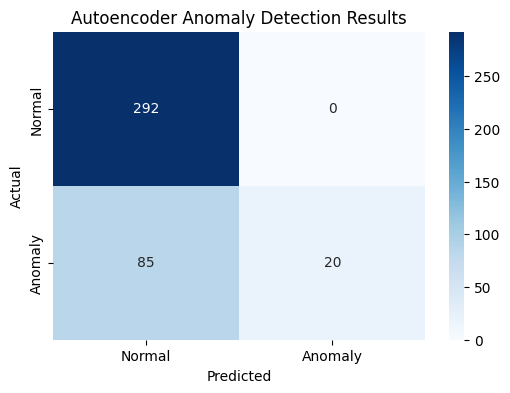

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare the Test Data
test_tensor = torch.tensor(X_test, dtype=torch.long)
target_tensor = torch.tensor(X_test, dtype=torch.long) # Autoencoder tries to output its input
test_loader = DataLoader(TensorDataset(test_tensor, target_tensor), batch_size=32, shuffle=False)

model.eval()
test_losses = []

# We use reduction='none' to isolate the error of each individual sequence, rather than an average of the batch
eval_criterion = nn.CrossEntropyLoss(ignore_index=0, reduction='none')

print("Evaluating test dataset...")

# 2. Calculate Reconstruction Error for the Test Set
with torch.no_grad():
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)

        output = model(data)

        # Reshape for CrossEntropyLoss: from (Batch, Window, Vocab) to (Batch, Vocab, Window)
        output = output.transpose(1, 2)

        # Calculate loss per token, then average it across the 20-log window
        loss = eval_criterion(output, target)
        seq_loss = loss.mean(dim=1)

        test_losses.extend(seq_loss.cpu().numpy())

test_losses = np.array(test_losses)

# 3. Define the Dynamic Threshold
# A common practice is setting the threshold at a high percentile (e.g., 95th) of the test losses
threshold = np.percentile(test_losses, 95)
print(f"Calculated Anomaly Threshold (Reconstruction Error): {threshold:.4f}\n")

# 4. Classify sequences
# If a sequence's reconstruction error is strictly greater than the threshold, flag it as 1 (Anomaly)
y_pred = (test_losses > threshold).astype(int)

# 5. Output the Results
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Anomaly (1)"]))

# 6. Visualize the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Autoencoder Anomaly Detection Results')
plt.show()

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. Define the Baseline Rule
# Identify which event tokens correspond to critical system alerts (Warning, Error, Severe, Fatal)
critical_levels = ['WARNING', 'ERROR', 'SEVERE', 'FATAL', 'FAILURE']
critical_tokens = df[df['Level'].isin(critical_levels)]['Event_Token'].unique()

# Our static threshold: Flag an anomaly if a sequence contains MORE THAN 0 critical logs
static_threshold_count = 0

baseline_preds = []

# 2. Apply the rule to the exact same test sequences (X_test) used for the Autoencoder
for seq in X_test:
    # Count how many critical tokens appear in this 20-log window
    critical_count = sum([1 for token in seq if token in critical_tokens])

    if critical_count > static_threshold_count:
        baseline_preds.append(1)  # Flag as Anomaly
    else:
        baseline_preds.append(0)  # Flag as Normal

# 3. Generate side-by-side metrics
print("--- THRESHOLD-BASED BASELINE RESULTS ---")
print(classification_report(y_test, baseline_preds, target_names=["Normal (0)", "Anomaly (1)"]))

print("\n--- DEEP LEARNING (AUTOENCODER) RESULTS ---")
# y_pred is the variable we generated in the previous Autoencoder evaluation cell
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Anomaly (1)"]))

# 4. Direct F1-Score Comparison
baseline_f1 = f1_score(y_test, baseline_preds)
ae_f1 = f1_score(y_test, y_pred)

print(f"\nFinal F1-Score Comparison:")
print(f"Baseline Threshold: {baseline_f1:.4f}")
print(f"LSTM Autoencoder:   {ae_f1:.4f}")

--- THRESHOLD-BASED BASELINE RESULTS ---
              precision    recall  f1-score   support

  Normal (0)       1.00      0.71      0.83       292
 Anomaly (1)       0.55      1.00      0.71       105

    accuracy                           0.78       397
   macro avg       0.77      0.85      0.77       397
weighted avg       0.88      0.78      0.80       397


--- DEEP LEARNING (AUTOENCODER) RESULTS ---
              precision    recall  f1-score   support

  Normal (0)       0.77      1.00      0.87       292
 Anomaly (1)       1.00      0.19      0.32       105

    accuracy                           0.79       397
   macro avg       0.89      0.60      0.60       397
weighted avg       0.83      0.79      0.73       397


Final F1-Score Comparison:
Baseline Threshold: 0.7095
LSTM Autoencoder:   0.3200


# **THIS IS FOR 4 MILLION ROW DATASET**

# **Version 2.0**

In [1]:
# ==========================================
# CELL 1: SETUP, PARSING & TEMPLATE MAPPING
# ==========================================
from google.colab import drive
import pandas as pd
import numpy as np
import re
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
print("Requesting Drive access...")
drive.mount('/content/drive')
!unzip "/content/drive/MyDrive/BGL Log/BGL.log.zip" -d /content/

Requesting Drive access...
Mounted at /content/drive
Archive:  /content/drive/MyDrive/BGL Log/BGL.log.zip
  inflating: /content/BGL.log        


In [3]:
drive.flush_and_unmount()

Beginning parsing of massive dataset...
Parsed 500,000 lines...
Parsed 1,000,000 lines...
Parsed 1,500,000 lines...
Parsed 2,000,000 lines...
Parsed 2,500,000 lines...
Parsed 3,000,000 lines...
Parsed 3,500,000 lines...
Parsed 4,000,000 lines...
Parsed 4,500,000 lines...
Parsing Complete: 4,713,493 total logs in 73.05 seconds.
Mapped 46,510 unique event templates to stable integer IDs.

Chronological Split - Train: 3,299,445, Val: 471,349, Test: 942,699 logs.
Generated Training Windows: 659,886
Generated Validation Windows: 94,266
Generated Testing Windows: 188,536

Model initialized on: cuda
Starting Training for 15 epochs...
Epoch [1/15] | Average Reconstruction Loss: 2.9684
Epoch [2/15] | Average Reconstruction Loss: 1.4788
Epoch [3/15] | Average Reconstruction Loss: 1.0455
Epoch [4/15] | Average Reconstruction Loss: 0.8552
Epoch [5/15] | Average Reconstruction Loss: 0.7361
Epoch [6/15] | Average Reconstruction Loss: 0.6588
Epoch [7/15] | Average Reconstruction Loss: 0.6009
Epoch [8

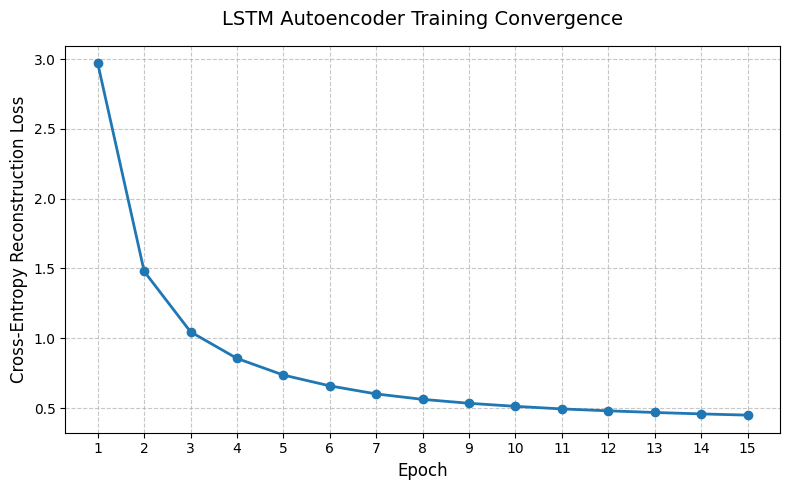


Calculating dynamic threshold from Validation Set...
Calibrated 90th-Percentile Threshold: 21.7844
Evaluating frozen threshold on unseen Test Set...

--- RULE-BASED SEVERITY DETECTOR (BASELINE) ---
              precision    recall  f1-score   support

  Normal (0)       0.95      0.99      0.97    176508
 Anomaly (1)       0.54      0.24      0.33     12028

    accuracy                           0.94    188536
   macro avg       0.74      0.61      0.65    188536
weighted avg       0.92      0.94      0.93    188536


--- DEEP LEARNING (LSTM AUTOENCODER) ---
              precision    recall  f1-score   support

  Normal (0)       0.95      0.90      0.92    176508
 Anomaly (1)       0.19      0.36      0.25     12028

    accuracy                           0.86    188536
   macro avg       0.57      0.63      0.59    188536
weighted avg       0.90      0.86      0.88    188536


Final F1-Score Comparison:
Rule-Based Baseline: 0.3275
LSTM Autoencoder:    0.2486


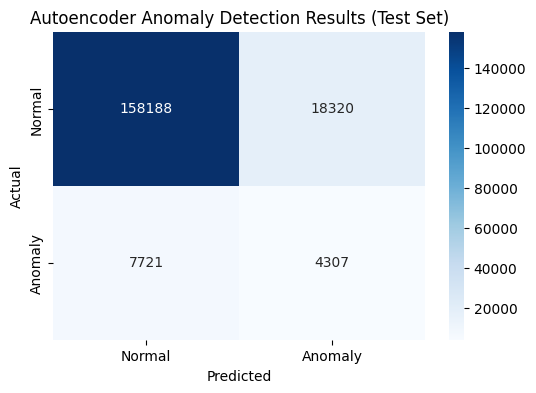

In [4]:
file_path = 'BGL.log'

bgl_pattern = re.compile(
    r'^(?P<Label>\S+)\s+(?P<Timestamp>\d+)\s+(?P<Date>\d{4}\.\d{2}\.\d{2})\s+'
    r'(?P<Node>\S+)\s+(?P<Time>\d{4}-\d{2}-\d{2}-\d{2}\.\d{2}\.\d{2}\.\d+)\s+'
    r'(?P<NodeRepeat>\S+)\s+(?P<Type>\S+)\s+(?P<Component>\S+)\s+'
    r'(?P<Level>\S+)\s+(?P<Content>.*)$'
)

parsed_logs = []
start_time = time.time()

print("Beginning parsing of massive dataset...")
with open(file_path, 'r') as file:
    for i, line in enumerate(file, start=1):
        match = bgl_pattern.match(line.strip())
        if match:
            log_dict = match.groupdict()
            parsed_logs.append(log_dict)

        if i % 500000 == 0:
            print(f"Parsed {i:,} lines...")

df = pd.DataFrame(parsed_logs)

# 1. Generate Labels and Mask Variables
df['Is_Anomaly'] = df['Label'].apply(lambda x: 0 if x == '-' else 1)

def extract_bgl_template(content):
    t = re.sub(r'0x[a-fA-F0-9]+', '<*>', content)
    t = re.sub(r'\d+\.\d+\.\d+\.\d+', '<*>', t)
    t = re.sub(r'[A-Z0-9]+-[A-Z0-9]+-[A-Z0-9]+-[A-Z0-9]+:[A-Z0-9]+-[A-Z0-9]+', '<*>', t)
    t = re.sub(r'\b\d+\b', '<*>', t)
    return t

df['Event template'] = df['Content'].apply(extract_bgl_template)

# 2. Methodological Fix: Direct Dictionary Mapping (No MD5 Hash Collisions)
unique_templates = df['Event template'].unique()
template_to_id = {template: idx + 1 for idx, template in enumerate(unique_templates)}
df['Event_Token'] = df['Event template'].map(template_to_id)

df = df[['Timestamp', 'Is_Anomaly', 'Component', 'Level', 'Event_Token', 'Event template']]
print(f"Parsing Complete: {len(df):,} total logs in {round(time.time() - start_time, 2)} seconds.")
print(f"Mapped {len(unique_templates):,} unique event templates to stable integer IDs.")


# ==========================================
# CELL 2: CHRONOLOGICAL SPLIT & WINDOWING
# ==========================================
# 1. Methodological Fix: Split data chronologically BEFORE windowing to prevent leakage
n_total = len(df)
train_idx = int(n_total * 0.7)
val_idx = int(n_total * 0.8)

train_df = df.iloc[:train_idx].copy()
val_df = df.iloc[train_idx:val_idx].copy()
test_df = df.iloc[val_idx:].copy()

print(f"\nChronological Split - Train: {len(train_df):,}, Val: {len(val_df):,}, Test: {len(test_df):,} logs.")

# 2. Windowing Function
def create_windows(data_subset, window_size=20, step_size=5):
    tokens = data_subset['Event_Token'].values
    anomaly_flags = data_subset['Is_Anomaly'].values

    sequences = []
    labels = []

    for i in range(0, len(tokens) - window_size + 1, step_size):
        seq = tokens[i:i + window_size]
        window_labels = anomaly_flags[i:i + window_size]

        # Methodological definition: Window is anomalous if it contains >= 1 anomaly
        window_is_anomaly = 1 if window_labels.sum() > 0 else 0

        sequences.append(seq)
        labels.append(window_is_anomaly)

    return np.array(sequences), np.array(labels)

X_train, y_train = create_windows(train_df)
X_val, y_val = create_windows(val_df)
X_test, y_test = create_windows(test_df)

print(f"Generated Training Windows: {len(X_train):,}")
print(f"Generated Validation Windows: {len(X_val):,}")
print(f"Generated Testing Windows: {len(X_test):,}")

# Isolate Normal Data for Autoencoder Training
X_train_normal = X_train[y_train == 0]


# ==========================================
# CELL 3: PYTORCH ARCHITECTURE & TRAINING
# ==========================================
batch_size = 512
vocab_size = len(template_to_id) + 1

train_tensor = torch.tensor(X_train_normal, dtype=torch.long)
train_loader = DataLoader(TensorDataset(train_tensor, train_tensor), batch_size=batch_size, shuffle=True)

val_tensor = torch.tensor(X_val, dtype=torch.long)
val_target_tensor = torch.tensor(X_val, dtype=torch.long)
val_loader = DataLoader(TensorDataset(val_tensor, val_target_tensor), batch_size=batch_size, shuffle=False)

test_tensor = torch.tensor(X_test, dtype=torch.long)
test_target_tensor = torch.tensor(X_test, dtype=torch.long)
test_loader = DataLoader(TensorDataset(test_tensor, test_target_tensor), batch_size=batch_size, shuffle=False)

class LogAutoencoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=16, hidden_dim=32):
        super(LogAutoencoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.encoder = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.decoder = nn.LSTM(hidden_dim, embedding_dim, batch_first=True)
        self.output_layer = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.encoder(embedded)
        hidden_repeated = hidden.repeat(x.size(1), 1, 1).transpose(0, 1)
        decoded, _ = self.decoder(hidden_repeated)
        return self.output_layer(decoded)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LogAutoencoder(vocab_size).to(device)
print(f"\nModel initialized on: {device}")

criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Methodological Fix: 15 Epochs for definitive convergence
epochs = 15
epoch_losses = []

print(f"Starting Training for {epochs} epochs...")
model.train()

for epoch in range(epochs):
    total_loss = 0
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)

        output = output.view(-1, vocab_size)
        target = target.view(-1)

        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    epoch_losses.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}] | Average Reconstruction Loss: {avg_loss:.4f}")

# Plot Convergence Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), epoch_losses, marker='o', linestyle='-', color='#1f77b4', linewidth=2)
plt.title('LSTM Autoencoder Training Convergence', fontsize=14, pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Cross-Entropy Reconstruction Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(range(1, epochs + 1))
plt.tight_layout()
plt.show()


# ==========================================
# CELL 4: VALIDATION THRESHOLD & TEST EVALUATION
# ==========================================
model.eval()
eval_criterion = nn.CrossEntropyLoss(ignore_index=0, reduction='none')

def get_reconstruction_errors(loader):
    losses = []
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            output = output.transpose(1, 2)

            loss = eval_criterion(output, target)
            seq_loss = loss.mean(dim=1)
            losses.extend(seq_loss.cpu().numpy())
    return np.array(losses)

# 1. Methodological Fix: Calculate Threshold ONLY from Validation Data
print("\nCalculating dynamic threshold from Validation Set...")
val_losses = get_reconstruction_errors(val_loader)
threshold = np.percentile(val_losses, 90)
print(f"Calibrated 90th-Percentile Threshold: {threshold:.4f}")

# 2. Evaluate on Test Data using the Frozen Threshold
print("Evaluating frozen threshold on unseen Test Set...")
test_losses = get_reconstruction_errors(test_loader)
y_pred = (test_losses > threshold).astype(int)

# 3. Methodological Fix: Define Rule-Based Severity Baseline ONLY from Training Data
critical_levels = ['WARNING', 'ERROR', 'SEVERE', 'FATAL', 'FAILURE']
critical_tokens = train_df[train_df['Level'].isin(critical_levels)]['Event_Token'].unique()

# Fast intersection to check for critical tokens in each test window
baseline_preds = [1 if np.isin(seq, critical_tokens).any() else 0 for seq in X_test]

# 4. Final Output Comparison
print("\n--- RULE-BASED SEVERITY DETECTOR (BASELINE) ---")
print(classification_report(y_test, baseline_preds, target_names=["Normal (0)", "Anomaly (1)"]))

print("\n--- DEEP LEARNING (LSTM AUTOENCODER) ---")
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Anomaly (1)"]))

print(f"\nFinal F1-Score Comparison:")
print(f"Rule-Based Baseline: {f1_score(y_test, baseline_preds):.4f}")
print(f"LSTM Autoencoder:    {f1_score(y_test, y_pred):.4f}")

# Generate Confusion Matrix for Autoencoder
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Autoencoder Anomaly Detection Results (Test Set)')
plt.show()